# DINOv2 ViT-S/14 → OpenVINO (FP32 / FP16 / INT8): step-by-step, end-to-end

A **standalone** notebook that converts the **DINOv2 ViT-S/14** backbone
([`facebook/dinov2-small`](https://huggingface.co/facebook/dinov2-small),
self-supervised web-scale checkpoint, [paper](https://arxiv.org/abs/2304.07193),
[GitHub](https://github.com/facebookresearch/dinov2)) to OpenVINO and compares
every precision against the original PyTorch model on a single sample image —
throughout, on **dense per-patch features**, the representation DINOv2 uses for
dense tasks (segmentation, correspondence, PCA).

**What this notebook does, in order:**

1. Set up a dedicated virtual environment (`.dinov2s-nb-venv`) as the Jupyter
   kernel; every dependency is then **pre-checked** in that kernel and only the
   missing packages are pip-installed.
2. Download the DINOv2 ViT-S/14 weights **once** into `checkpoints/` and load
   them into a small **inline implementation** of the architecture — the
   notebook needs no model library, only `torch`.
3. Download **one sample image** (the dog photo used across the DINO examples)
   **once** into `data/`.
4. Convert the model to OpenVINO IR in **FP32** (unquantized baseline),
   **FP16** and **INT8** under
   `ov_models/`. All three are built from an **optimized export graph**
   (split Q/K/V projections, fused token prefix, approximate-form GELU) that
   outputs the **dense per-patch features** `(B, D, h, w)`, traced directly in
   FP16. INT8 uses **NNCF PTQ** (`nncf.quantize`)
   calibrated on a strided subset of the ImageNet validation images when they
   are present, and **weights-only quantization** (`nncf.compress_weights`,
   INT8 symmetric) otherwise.
5. Run **each** OpenVINO model end-to-end on the sample image.
6. Quantify fidelity with the measure the DINO lineage uses to characterize
   dense features — **cosine similarity**, complemented by **MSE** and **MAE**.
7. Report **latency** for each engine: PyTorch on **CPU** and — when an XPU
   build is available — on the **Intel GPU**, plus OpenVINO on the selected
   device.
8. Visualize the dense features with **PCA**, **segmentation** and a per-patch
   **cosine-similarity** map (torch vs each precision).

> **Everything is built live and cached.** The weights, the sample image and
> the exported IRs are downloaded/converted on the first run and written next
> to the notebook; a re-run skips the downloads and the conversion — and prints
> that it did — so only inference, metrics and plots are recomputed.
> **INT8 recipes.** PTQ calibrates the quantizers from a strided subset of the
> ImageNet validation images (`datasets/imagenet/val`, or point `CALIB_DIR` at
> any image folder tree in the configuration cell). When that set is missing,
> INT8 falls back to **weights-only quantization**, which needs no calibration
> data at all, so both precisions still run end-to-end. The recipe actually
> used is printed at conversion time and carried through the tables.
> **No register tokens.** This is the base DINOv2 checkpoint: the token
> sequence is `[CLS] + [patch tokens]` (the register-token variant is a
> separate checkpoint, `dinov2-small-reg`).

### Installation Instructions

This is a self-contained example that relies solely on its own code.

We recommend  running the notebook in a virtual environment. You only need a Jupyter server to start.
For details, please refer to [Installation Guide](https://github.com/openvinotoolkit/openvino_notebooks/blob/latest/README.md#-installation-guide).

#### Table of contents:

- [1. Install dependencies](#1.-Install-dependencies)
- [2. Imports & configuration](#2.-Imports-&-configuration)
- [3. Download & load the DINOv2 ViT-S/14 model](#3.-Download-&-load-the-DINOv2-ViT-S/14-model)
- [4. Get a sample image](#4.-Get-a-sample-image)
- [5. Torch reference features (ground truth)](#5.-Torch-reference-features-(ground-truth))
- [6. OpenVINO conversion → FP32 / FP16 / INT8](#6.-OpenVINO-conversion-→-FP32-/-FP16-/-INT8)
- [7. Run each OpenVINO model on the sample image](#7.-Run-each-OpenVINO-model-on-the-sample-image)
- [8. Fidelity metrics vs the torch model](#8.-Fidelity-metrics-vs-the-torch-model)
- [9. Latency](#9.-Latency)
- [10. Visualization — PCA & segmentation (torch vs OpenVINO)](#10.-Visualization-—-PCA-&-segmentation-(torch-vs-OpenVINO))
- [11. Summary](#11.-Summary)

<img referrerpolicy="no-referrer-when-downgrade" src="https://static.scarf.sh/a.png?x-pxid=5b5a4db0-7875-4bfb-bdbd-01698b5b1a77&file=notebooks/dinov2-s/dinov2-s.ipynb" />

## 1. Install dependencies

This notebook sets up its own environment. The first cell bootstraps a
**dedicated virtual environment** (`.dinov2s-nb-venv`) and registers it as a
Jupyter kernel — idempotently, so re-runs are instant and the running kernel is
never touched. When an Intel GPU is visible the bootstrap installs the **XPU
build of torch** into the virtual environment, so the PyTorch latency row for the Intel GPU is
available after switching to the new kernel; on any other machine it installs
the CPU build. The second cell then makes the **running** kernel self-sufficient
with the same stack (OpenVINO-notebook methodology), so the notebook also works
end-to-end without switching kernels.

**Pre-checks first, installs second:** every requirement is probed with an
import check and only genuinely missing packages are pip-installed — a kernel
that already has the stack pays no install cost at all, and re-runs are instant.

- **torch / torchvision** come from the **XPU wheel index** when an Intel GPU is
  present and from the **CPU index** otherwise: the PyTorch reference runs on
  CPU and — on an XPU build — on the Intel GPU, while the OpenVINO engines use
  the Intel GPU/CPU through the OpenVINO runtime (which has no torch
  dependency). Any existing torch build is kept as-is.

> **GPU note.** The OpenVINO device is auto-selected in the next section. If the
> Level Zero driver for the Intel GPU aborts device enumeration (a known
> driver/kernel mismatch on some systems), the notebook detects it and falls
> back to **CPU** automatically — the rest of the notebook runs unchanged.

In [1]:
# === Bootstrap the dedicated kernel (.dinov2s-nb-venv) =======================
# Creates the venv, installs the stack into it and registers it as a Jupyter
# kernel — every step skipped when already done. The running kernel is never
# modified by this cell; after it completes, select "Python (.dinov2s-nb-venv)"
# and re-run to execute the notebook inside the dedicated environment.
import glob
import os
import subprocess
import sys
from pathlib import Path

VENV_DIR = Path(".dinov2s-nb-venv")
KERNEL_NAME = "dinov2s-nb-venv"
DISPLAY_NAME = "Python (.dinov2s-nb-venv)"
VENV_PY = VENV_DIR / ("Scripts/python.exe" if os.name == "nt" else "bin/python")

# An Intel GPU is visible when a DRM render node exists (Linux); that is where
# the XPU torch wheels are the right build. Everywhere else use the CPU index.
INTEL_GPU = sys.platform.startswith("linux") and bool(glob.glob("/dev/dri/renderD*"))
TORCH_INDEX = "https://download.pytorch.org/whl/xpu" if INTEL_GPU else "https://download.pytorch.org/whl/cpu"


def venv_missing(modules):
    """Names among ``modules`` the venv interpreter cannot resolve (one probe)."""
    probe = "import importlib.util, sys; " "print(','.join(m for m in sys.argv[1:] if importlib.util.find_spec(m) is None))"
    out = subprocess.run([str(VENV_PY), "-c", probe, *modules], capture_output=True, text=True, check=True)
    found = out.stdout.strip()
    return found.split(",") if found else []


def venv_pip(*args):
    subprocess.run([str(VENV_PY), "-m", "pip", "install", "-q", *args], check=True)


REQUIRED = [
    ("ipykernel", "ipykernel"),
    ("torch", None),  # handled below: needs an extra index url
    ("openvino", "openvino>=2025.1"),
    ("nncf", "nncf>=2.13"),
    ("safetensors", "safetensors"),
    ("huggingface_hub", "huggingface_hub>=0.24"),
    ("PIL", "pillow"),
    ("numpy", "numpy"),
    ("matplotlib", "matplotlib"),
    ("sklearn", "scikit-learn"),
    ("requests", "requests"),
    ("ipywidgets", "ipywidgets"),
]

if not VENV_PY.exists():
    print(f"creating {VENV_DIR}/ ...")
    subprocess.run([sys.executable, "-m", "venv", str(VENV_DIR)], check=True)

missing = set(venv_missing([mod for mod, _ in REQUIRED]))
for mod, spec in REQUIRED:
    if mod not in missing:
        continue
    if mod == "torch":
        print(f"  torch            missing -> pip install torch torchvision ({TORCH_INDEX})")
        venv_pip("--extra-index-url", TORCH_INDEX, "torch", "torchvision")
    else:
        print(f"  {mod:<16} missing -> pip install {spec}")
        venv_pip(spec)
if not missing:
    print("venv already has the full stack")

# Kernel registration is cheap and idempotent (it rewrites the kernelspec).
subprocess.run(
    [str(VENV_PY), "-m", "ipykernel", "install", "--user", "--name", KERNEL_NAME, "--display-name", DISPLAY_NAME],
    check=True,
    stdout=subprocess.DEVNULL,
)

# sys.prefix is the venv root; comparing executables would follow the venv's
# python symlink back to the base interpreter and match spuriously.
if Path(sys.prefix).resolve() == VENV_DIR.resolve():
    import torch

    print(f"\nrunning inside {VENV_DIR}: torch {torch.__version__}, " f"xpu available: {torch.xpu.is_available()}")
else:
    print(
        f"\nkernel '{DISPLAY_NAME}' is ready. Select it (Kernel > Change kernel) "
        "and re-run to execute in the dedicated environment; the notebook "
        "continues on the current kernel meanwhile."
    )

venv already has the full stack

running inside .dinov2s-nb-venv: torch 2.14.1+xpu, xpu available: True


In [2]:
# === Install dependencies into the active Jupyter kernel ======================
# Pre-check first: every requirement is probed with importlib.util.find_spec and
# only the missing packages are pip-installed, so a kernel that already has the
# stack pays no install cost at all (not even a pip resolution pass).
import importlib.util
import subprocess
import sys


def pip_install(*args):
    """Install packages into the active kernel (OpenVINO-notebook methodology)."""
    cli = []
    for a in args:
        cli.extend(str(a).split(" "))
    subprocess.run([sys.executable, "-m", "pip", "install", *cli], check=True)


# Recommend the dedicated venv (openvino_notebooks practice); warn, never fail,
# because CI runs this notebook inside a managed environment on purpose.
if sys.prefix == sys.base_prefix:
    print(
        "note: the kernel is not inside a virtual environment; create .dinov2s-nb-venv "
        "as described above and re-select it (installing into the current kernel anyway)"
    )


def ensure(import_name, pip_spec):
    """Install ``pip_spec`` only when ``import_name`` cannot be resolved."""
    if importlib.util.find_spec(import_name) is None:
        print(f"  {import_name:<16} missing -> pip install {pip_spec}")
        pip_install("-q", pip_spec)
    else:
        print(f"  {import_name:<16} already present")


# --- torch / torchvision: keep whatever torch the kernel already has ----------
# The XPU wheel index is used when an Intel GPU is visible (matching the
# bootstrap cell), the CPU index otherwise, so a kernel with no torch still
# gets a working build on any machine.
if importlib.util.find_spec("torch") is None:
    import glob as _glob

    _index = (
        "https://download.pytorch.org/whl/xpu"
        if sys.platform.startswith("linux") and _glob.glob("/dev/dri/renderD*")
        else "https://download.pytorch.org/whl/cpu"
    )
    pip_install("-q", "--extra-index-url", _index, "torch", "torchvision")
else:
    print("  torch            already present")

for _mod, _spec in [
    ("openvino", "openvino>=2025.1"),
    ("nncf", "nncf>=2.13"),
    ("safetensors", "safetensors"),
    ("huggingface_hub", "huggingface_hub>=0.24"),
    ("PIL", "pillow"),
    ("numpy", "numpy"),
    ("matplotlib", "matplotlib"),
    ("sklearn", "scikit-learn"),
    ("requests", "requests"),
    ("ipywidgets", "ipywidgets"),
]:
    ensure(_mod, _spec)

import importlib

print("\ndependencies ready in", sys.executable)
for m in ["openvino", "nncf", "torch", "torchvision", "safetensors", "huggingface_hub", "PIL", "numpy", "matplotlib", "sklearn", "requests"]:
    try:
        mod = importlib.import_module(m)
        print(f"  {m:<16} {getattr(mod, '__version__', 'ok')}")
    except Exception as exc:
        print(f"  {m:<16} MISSING -> {exc}")

# --- telemetry (openvino_notebooks CI) ---------------------------------------
# Fetch the shared helper and report that this notebook was run.
import urllib.request
from pathlib import Path

if not Path("notebook_utils.py").exists():
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/openvinotoolkit/openvino_notebooks/latest/utils/notebook_utils.py",
        "notebook_utils.py",
    )

# Read more about telemetry collection at https://github.com/openvinotoolkit/openvino_notebooks?tab=readme-ov-file#-telemetry
from notebook_utils import collect_telemetry

collect_telemetry("dinov2-s.ipynb")

  torch            already present
  openvino         already present
  nncf             already present
  safetensors      already present
  huggingface_hub  already present
  PIL              already present
  numpy            already present
  matplotlib       already present
  sklearn          already present
  requests         already present
  ipywidgets       already present

dependencies ready in /home/naga/projects/dinov2-s/dinov2s-v1/notebooks/dinov2-s/.dinov2s-nb-venv/bin/python
  openvino         2026.4.1-22982-e213a147257-releases/2026/4
  nncf             3.4.0
  torch            2.14.1+xpu
  torchvision      0.29.1+xpu
  safetensors      0.8.0
  huggingface_hub  2.3.0
  PIL              12.3.0
  numpy            2.4.6
  matplotlib       3.11.2
  sklearn          1.9.1
  requests         2.34.2


## 2. Imports & configuration

Central knobs: the Hugging Face model id, the evaluation resolution, and the
OpenVINO device (auto-selects the Intel **GPU** if present, else **CPU**).

Three folders are created next to the notebook and **reused across runs** — this
is what makes the notebook cheap to re-run:

| folder | contents | re-run behaviour |
|---|---|---|
| `checkpoints/` | DINOv2 ViT-S/14 weights | download skipped if present |
| `data/` | the sample image | download skipped if present |
| `ov_models/` | the FP32 / FP16 / INT8 OpenVINO IRs | conversion skipped if present |

In [3]:
import copy
import json
import math
import subprocess
import time
from pathlib import Path

import matplotlib.pyplot as plt
import nncf
import numpy as np
import openvino as ov
import requests
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T
from PIL import Image

torch.manual_seed(0)
torch.set_grad_enabled(False)  # inference only

# --- model source -------------------------------------------------------------
# facebook/dinov2-small is the LVD-142M ViT-S/14 backbone published by the DINOv2
# authors; the repository does not require a login or token.
HF_MODEL_ID = "facebook/dinov2-small"

# Architecture constants of ViT-S/14 (as in the config shipped with the checkpoint).
PATCH = 14  # patch size in pixels
EMBED = 384  # hidden size
HEADS = 6  # attention heads
DEPTH = 12  # transformer blocks
MLP_RATIO = 4  # feed-forward expansion

# --- persistent artifact folders (created once, reused on every re-run) -------
REPO_ROOT = Path.cwd()
CHECKPOINT_DIR = REPO_ROOT / "checkpoints" / HF_MODEL_ID.split("/")[-1]
DATA_DIR = REPO_ROOT / "data"
OV_DIR = REPO_ROOT / "ov_models"
for _dir in (CHECKPOINT_DIR, DATA_DIR, OV_DIR):
    _dir.mkdir(parents=True, exist_ok=True)

# --- inference config ---------------------------------------------------------
IMAGE_SIZE = 518  # DINOv2 native resolution (37 x 14-px patches)
BENCH_REPEATS = 20  # timed iterations for latency

# --- INT8 calibration (PTQ) ----------------------------------------------------
# nncf.quantize needs a small set of representative images to collect activation
# statistics. A strided subset of the ImageNet validation folders spans all 1000
# classes and needs no labels. When no local set is found, INT8 falls back to
# weights-only quantization (no data needed).
# Candidates: alongside the notebook, at the openvino_notebooks repo root (one
# level up), and at this repository's root when the notebook sits two levels below it.
_calib_candidates = [
    REPO_ROOT / "datasets" / "imagenet" / "val",
    REPO_ROOT.parent / "datasets" / "imagenet" / "val",
    REPO_ROOT.parent.parent / "datasets" / "imagenet" / "val",
]
CALIB_DIR = next((p for p in _calib_candidates if p.exists()), None)
CALIB_SAMPLES = 512  # images used for PTQ calibration (strided subset)


def probe_ov_devices():
    """Return OpenVINO's available devices, or None if the probe crashes.

    On some systems the Level Zero (GPU) driver aborts the *process* (SIGABRT)
    when OpenVINO enumerates devices. A SIGABRT cannot be caught in Python, so
    the probe runs in a short-lived child process: if it dies, we fall back to
    CPU instead of taking the whole kernel down with it.
    """
    code = "import openvino as ov, json, sys;" "print(json.dumps(ov.Core().available_devices))"
    try:
        r = subprocess.run([sys.executable, "-c", code], capture_output=True, text=True, timeout=120)
    except Exception:
        return None
    if r.returncode != 0:
        return None
    for line in reversed(r.stdout.splitlines()):
        line = line.strip()
        if line.startswith("["):
            try:
                return json.loads(line)
            except Exception:
                return None
    return None


_devices = probe_ov_devices()
if _devices and "GPU" in _devices:
    DEVICE = "GPU"
    print(f"OpenVINO devices: {_devices}  ->  using '{DEVICE}'")
else:
    DEVICE = "CPU"
    if _devices is None:
        print("OpenVINO device probe aborted (GPU driver issue) -> using 'CPU'")
    else:
        print(f"OpenVINO devices: {_devices}  ->  no GPU, using 'CPU'")

# --- torch bench devices -------------------------------------------------------
# PyTorch is timed on CPU and, when an XPU build is available, on the Intel GPU.
TORCH_DEVICES = ["cpu"] + (["xpu"] if torch.xpu.is_available() else [])

print(f"Model id     : {HF_MODEL_ID}")
print(f"Image size   : {IMAGE_SIZE}px")
print(f"checkpoints  : {CHECKPOINT_DIR}")
print(f"sample data  : {DATA_DIR}")
print(f"OpenVINO IRs : {OV_DIR}")
print(f"torch devices: {', '.join(TORCH_DEVICES)}")
if CALIB_DIR is not None:
    _calib_note = f"{CALIB_DIR} (local)"
else:
    _calib_note = "not found -> INT8 PTQ is skipped, weights-only INT8 is used instead"
print(f"INT8 calib   : {_calib_note}  [{CALIB_SAMPLES} images]")

OpenVINO devices: ['CPU', 'GPU', 'NPU']  ->  using 'GPU'
Model id     : facebook/dinov2-small
Image size   : 518px
checkpoints  : /home/naga/projects/dinov2-s/dinov2s-v1/notebooks/dinov2-s/checkpoints/dinov2-small
sample data  : /home/naga/projects/dinov2-s/dinov2s-v1/notebooks/dinov2-s/data
OpenVINO IRs : /home/naga/projects/dinov2-s/dinov2s-v1/notebooks/dinov2-s/ov_models
torch devices: cpu, xpu
INT8 calib   : /home/naga/projects/dinov2-s/dinov2s-v1/datasets/imagenet/val (local)  [512 images]


In [4]:
import ipywidgets as widgets

# Device selection widget. The options come from the child-process probe in the
# cell above (which guards against the Level Zero abort), so we never call
# core.available_devices directly in this kernel.
_device_options = list(_devices) if _devices else ["CPU"]
if "AUTO" not in _device_options:
    _device_options = ["AUTO"] + _device_options

device = widgets.Dropdown(
    options=_device_options,
    value=DEVICE,  # default to the probed choice from the cell above
    description="Device:",
    layout=widgets.Layout(width="320px"),
)
display(device)

# Resolve the selection: AUTO -> GPU when available, else CPU.
DEVICE = "GPU" if (device.value == "AUTO" and "GPU" in _device_options) else device.value
print(f"Selected OpenVINO device: {DEVICE}")

Dropdown(description='Device:', index=2, layout=Layout(width='320px'), options=('AUTO', 'CPU', 'GPU', 'NPU'), …

Selected OpenVINO device: GPU


## 3. Download & load the DINOv2 ViT-S/14 model

The weights are pulled from the Hugging Face Hub **into `checkpoints/`** on the
first run and loaded from there afterwards — the download is skipped when the
checkpoint is already on disk, and falls back to the local Hub cache if the
network is unavailable.

The notebook then defines the ViT-S/14 architecture **inline** (about 100 lines
of plain `torch.nn`: patch embedding, per-layer-scaled attention blocks, and the
position-embedding interpolation of the original model) and loads the weights
into it by mapping the Hugging Face parameter names onto the original ones —
the fused QKV projection is the concatenation of the separate query/key/value
matrices, so the mapping is exact, bit for bit. No model library is needed
beyond `torch` itself.

DINOv2's token sequence is `[CLS] + [patch tokens]` (this checkpoint has **no
register tokens**). The output this notebook works with is the

- **dense per-patch features** `(B, D, h, w)` — the CLS token is dropped and the
  patch tokens are reshaped onto the spatial grid. These are what segmentation /
  PCA consume, and they are the ground truth for every precision below.

In [5]:
import re
import shutil

from huggingface_hub import snapshot_download
from safetensors.torch import load_file

CKPT_PATTERNS = ["*.json", "*.safetensors"]


def fetch_checkpoint(repo_id, dst, patterns):
    """Materialize the weights in ``dst`` once; later runs load them straight from there."""
    if (dst / "model.safetensors").exists():
        print(f"checkpoint already present -> skipping download  ({dst})")
        return
    print(f"fetching {repo_id}  ->  {dst}")
    try:
        src = snapshot_download(repo_id=repo_id, allow_patterns=patterns)
    except Exception as exc:
        print(f"  Hub unreachable ({type(exc).__name__}) -> falling back to the local Hub cache")
        try:
            src = snapshot_download(repo_id=repo_id, allow_patterns=patterns, local_files_only=True)
        except Exception:
            raise RuntimeError(
                f"Could not obtain '{repo_id}' from the Hub or the local cache. " "Check the network connection (or a prior download) and re-run this cell."
            ) from exc
    dst.mkdir(parents=True, exist_ok=True)
    for f in Path(src).rglob("*"):
        if f.is_file():
            shutil.copy(f, dst / f.name)  # follows the cache symlinks -> real files in dst
    print(f"  copied {len(list(dst.glob('*')))} files into {dst}")


fetch_checkpoint(HF_MODEL_ID, CHECKPOINT_DIR, CKPT_PATTERNS)


# --- the ViT-S/14 architecture, inline ----------------------------------------
class LayerScale(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.gamma = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        return x * self.gamma


class Attention(nn.Module):
    def __init__(self, dim, heads):
        super().__init__()
        self.num_heads = heads
        self.qkv = nn.Linear(dim, dim * 3)
        self.proj = nn.Linear(dim, dim)

    def forward(self, x):
        b, length, channels = x.shape
        head_dim = channels // self.num_heads
        qkv = self.qkv(x).reshape(b, length, 3, self.num_heads, head_dim).permute(2, 0, 3, 1, 4)
        q, k, v = qkv.unbind(0)
        out = F.scaled_dot_product_attention(q, k, v)
        return self.proj(out.transpose(1, 2).reshape(b, length, channels))


class Mlp(nn.Module):
    def __init__(self, dim, hidden):
        super().__init__()
        self.fc1 = nn.Linear(dim, hidden)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(hidden, dim)
        self.drop = nn.Dropout(0.0)

    def forward(self, x):
        x = self.fc1(x)
        x = self.act(x)
        x = self.drop(x)
        x = self.fc2(x)
        x = self.drop(x)
        return x


class PatchEmbed(nn.Module):
    def __init__(self, patch):
        super().__init__()
        self.patch_size = (patch, patch)
        self.embed_dim = EMBED
        self.proj = nn.Conv2d(3, EMBED, kernel_size=patch, stride=patch)
        self.norm = nn.Identity()

    def forward(self, x):
        _, _, H, W = x.shape
        patch_H, patch_W = self.patch_size
        assert H % patch_H == 0, f"Input image height {H} is not a multiple of patch height {patch_H}"
        assert W % patch_W == 0, f"Input image width {W} is not a multiple of patch width: {patch_W}"
        x = self.proj(x)  # B C H W
        H, W = x.size(2), x.size(3)
        x = x.flatten(2).transpose(1, 2)  # B HW C
        x = self.norm(x)
        return x


class Block(nn.Module):
    def __init__(self, dim, heads, hidden):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim, eps=1e-6)
        self.attn = Attention(dim, heads)
        self.ls1 = LayerScale(dim)
        self.norm2 = nn.LayerNorm(dim, eps=1e-6)
        self.mlp = Mlp(dim, hidden)
        self.ls2 = LayerScale(dim)

    def forward(self, x):
        x = x + self.ls1(self.attn(self.norm1(x)))
        x = x + self.ls2(self.mlp(self.norm2(x)))
        return x


class DinoV2Backbone(nn.Module):
    """DINOv2 ViT-S/14 backbone (the original architecture, no register tokens)."""

    def __init__(self, num_prefix_tokens):
        super().__init__()
        self.patch_size = PATCH
        self.embed_dim = EMBED
        self.num_register_tokens = 0
        self.interpolate_offset = 0.1  # the original model's interpolation kludge
        self.interpolate_antialias = True
        self.patch_embed = PatchEmbed(PATCH)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, EMBED))
        self.pos_embed = nn.Parameter(torch.zeros(1, num_prefix_tokens, EMBED))
        self.register_tokens = None
        self.blocks = nn.ModuleList(Block(EMBED, HEADS, EMBED * MLP_RATIO) for _ in range(DEPTH))
        self.norm = nn.LayerNorm(EMBED, eps=1e-6)

    def interpolate_pos_encoding(self, x, w, h):
        previous_dtype = x.dtype
        npatch = x.shape[1] - 1
        N = self.pos_embed.shape[1] - 1
        if npatch == N and w == h:
            return self.pos_embed
        pos_embed = self.pos_embed.float()
        class_pos_embed = pos_embed[:, 0]
        patch_pos_embed = pos_embed[:, 1:]
        dim = x.shape[-1]
        w0 = w // self.patch_size
        h0 = h // self.patch_size
        M = int(math.sqrt(N))  # Recover the number of patches in each dimension
        assert N == M * M
        kwargs = {}
        if self.interpolate_offset:
            # Historical kludge: add a small number to avoid floating point error in the
            # interpolation, see https://github.com/facebookresearch/dino/issues/8
            sx = float(w0 + self.interpolate_offset) / M
            sy = float(h0 + self.interpolate_offset) / M
            kwargs["scale_factor"] = (sx, sy)
        else:
            kwargs["size"] = (w0, h0)
        patch_pos_embed = nn.functional.interpolate(
            patch_pos_embed.reshape(1, M, M, dim).permute(0, 3, 1, 2),
            mode="bicubic",
            antialias=self.interpolate_antialias,
            **kwargs,
        )
        assert (w0, h0) == patch_pos_embed.shape[-2:]
        patch_pos_embed = patch_pos_embed.permute(0, 2, 3, 1).view(1, -1, dim)
        return torch.cat((class_pos_embed.unsqueeze(0), patch_pos_embed), dim=1).to(previous_dtype)

    def forward(self, x):
        batch, _, width, height = x.shape
        x = self.patch_embed(x)
        x = torch.cat((self.cls_token.expand(x.shape[0], -1, -1), x), dim=1)
        x = x + self.interpolate_pos_encoding(x, width, height)
        for block in self.blocks:
            x = block(x)
        return self.norm(x)  # (B, 1 + h*w, D)


# --- load the Hugging Face weights into the inline architecture ----------------
def load_backbone(checkpoint_dir):
    """Map the Hugging Face parameter names onto the original ones and load them.

    The mapping is exact: the fused QKV matrix is the concatenation of the
    separate query/key/value matrices (bit-identical to the original checkpoint),
    ``layernorm.*`` is the final ``norm.*``, and ``layer_scaleN.lambda1`` is
    ``lsN.gamma``. The unused mask token is skipped.
    """
    hf = load_file(Path(checkpoint_dir) / "model.safetensors")
    sd = {}
    for k, v in hf.items():
        if k == "embeddings.cls_token":
            sd["cls_token"] = v
        elif k == "embeddings.position_embeddings":
            sd["pos_embed"] = v
        elif k == "embeddings.mask_token":
            continue  # masked-image modelling only; unused for inference
        elif k.startswith("embeddings.patch_embeddings.projection."):
            sd["patch_embed.proj." + k.rsplit(".", 1)[1]] = v
        elif k.startswith("layernorm."):
            sd["norm." + k.rsplit(".", 1)[1]] = v
        else:
            m = re.fullmatch(r"encoder\.layer\.(\d+)\.(.*)", k)
            assert m, k
            b, sub = m.group(1), m.group(2)
            qkv = re.fullmatch(r"attention\.attention\.(query|key|value)\.(weight|bias)", sub)
            if qkv:
                which = qkv.group(2)
                order = {"query": 0, "key": 1, "value": 2}[qkv.group(1)]
                dst = f"blocks.{b}.attn.qkv.{which}"
                sd.setdefault(dst, [None, None, None])[order] = v
                continue
            sub = sub.replace("attention.output.dense", "attn.proj")
            sub = re.sub(r"layer_scale(\d)\.lambda1", r"ls\1.gamma", sub)
            sd[f"blocks.{b}.{sub}"] = v
    for k, parts in list(sd.items()):
        if isinstance(parts, list):
            sd[k] = torch.cat(parts, dim=0)  # fused QKV = cat(query, key, value)
    backbone = DinoV2Backbone(num_prefix_tokens=hf["embeddings.position_embeddings"].shape[1])
    missing, unexpected = backbone.load_state_dict(sd, strict=False)
    assert not missing and not unexpected, (missing, unexpected)
    return backbone.eval()


backbone = load_backbone(CHECKPOINT_DIR)

assert IMAGE_SIZE % PATCH == 0, f"IMAGE_SIZE must be a multiple of the patch size ({PATCH})"
assert backbone.pos_embed.shape[1] - 1 == (IMAGE_SIZE // PATCH) ** 2, "IMAGE_SIZE must match the checkpoint's position grid"
GRID = IMAGE_SIZE // PATCH
print(f"patch_size={PATCH}  hidden={EMBED}  heads={HEADS}  layers={DEPTH}")
print(f"dense grid @ {IMAGE_SIZE}px: {GRID}x{GRID} = {GRID * GRID} patches x {EMBED}-d")


# Paper-faithful val transform (ImageNet statistics, as in the original model card).
def build_transform(image_size):
    """Resize short side, center-crop, normalize (the DINOv2 eval recipe)."""
    return T.Compose(
        [
            T.Resize(image_size, interpolation=T.InterpolationMode.BICUBIC),
            T.CenterCrop(image_size),
            T.ToTensor(),
            T.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ]
    )


transform = build_transform(IMAGE_SIZE)


def dense_features(tokens):
    """Normalized token sequence (B, 1 + h*w, D) -> dense features (B, D, h, w)."""
    grid = IMAGE_SIZE // PATCH
    patch = tokens[:, 1:, :].permute(0, 2, 1)  # (B, D, h*w), CLS dropped
    return patch.reshape(tokens.shape[0], EMBED, grid, grid)


print("model + transform ready")

checkpoint already present -> skipping download  (/home/naga/projects/dinov2-s/dinov2s-v1/notebooks/dinov2-s/checkpoints/dinov2-small)
patch_size=14  hidden=384  heads=6  layers=12
dense grid @ 518px: 37x37 = 1369 patches x 384-d
model + transform ready


## 4. Get a sample image

We evaluate on the same natural image the DINO examples use — the *dog*
photo — so the results are directly comparable across the DINO notebooks. It is
downloaded **once** into `data/` and reused on every later run, so the notebook
stays self-contained without re-fetching anything.

sample image already present -> skipping download  (/home/naga/projects/dinov2-s/dinov2s-v1/notebooks/dinov2-s/data/sample.jpg)
input tensor: (1, 3, 518, 518)


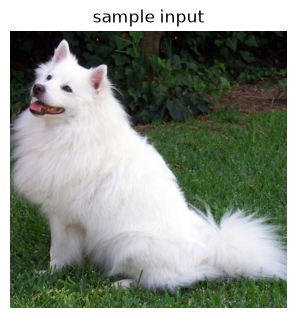

In [6]:
# Stable, well-known sample used in the PyTorch / DINO examples.
SAMPLE_URL = "https://raw.githubusercontent.com/pytorch/hub/master/images/dog.jpg"
SAMPLE_PATH = DATA_DIR / "sample.jpg"

if SAMPLE_PATH.exists():
    print(f"sample image already present -> skipping download  ({SAMPLE_PATH})")
else:
    resp = requests.get(SAMPLE_URL, timeout=30)
    resp.raise_for_status()
    SAMPLE_PATH.write_bytes(resp.content)
    print(f"downloaded {SAMPLE_URL}  ->  {SAMPLE_PATH}")

pil_image = Image.open(SAMPLE_PATH).convert("RGB")

# Model input + a display image (exactly the pixels the model sees).
pixel_values = transform(pil_image).unsqueeze(0)  # (1, 3, H, W)
_disp = T.CenterCrop(IMAGE_SIZE)(T.Resize(IMAGE_SIZE, interpolation=T.InterpolationMode.BICUBIC)(pil_image))
display_np = np.asarray(_disp)
print("input tensor:", tuple(pixel_values.shape))

plt.figure(figsize=(3.6, 3.6))
plt.imshow(display_np)
plt.title("sample input")
plt.axis("off")
plt.show()

## 5. Torch reference features (ground truth)

Run the PyTorch model once. Its dense features are the **reference** every
OpenVINO precision is compared against (both visually and via metrics).

In [7]:
with torch.inference_mode():
    ref_tokens = backbone(pixel_values)  # (1, 1 + h*w, D), final norm applied
ref_torch = dense_features(ref_tokens)  # (1, D, h, w)
print("torch dense features:", tuple(ref_torch.shape))


def to_rows(feat_bdhw):
    """(1, D, h, w) -> (h*w, D) rows, one row per patch, aligned across engines."""
    return feat_bdhw[0].movedim(0, -1).reshape(-1, EMBED).float()


ref_rows = to_rows(ref_torch)  # (h*w, D)
ref_hwd = ref_torch[0].movedim(0, -1).float()  # (h, w, D) for PCA/seg

torch dense features: (1, 384, 37, 37)


## 6. OpenVINO conversion → FP32 / FP16 / INT8

All three IRs are built live from the checkpoint downloaded in section 3 — the
notebook ships no models. The **FP32 baseline** is the same optimized graph
with unquantized FP32 weights, which anchors the fidelity and latency tables.
The FP16 and INT8 IRs are built from an **optimized export graph** — an
export-only rewrite of the backbone that is mathematically equivalent to the
torch model above:

- **Split Q/K/V projections.** The fused QKV matrix is stored as three
  projections writing attention-ready tensors directly (the weights are exact
  slices of the fused matrix), which removes per-block slice/reorder kernels.
- **Fused token prefix.** The CLS token plus its position embedding becomes one
  constant prefix concatenated once.
- **Approximate-form GELU** in the feed-forward blocks.

The graph outputs the **dense patch features** `(B, D, h, w)` — the
representation every later section compares. It is traced **directly in FP16**,
so the FP16 IR carries true half-precision constants and the INT8 IRs are
derived from the same graph. INT8 comes in two recipes:

- **PTQ** (`nncf.quantize`): MIXED preset, GPU target, transformer model type
  (attention stays FP16, the matrix products become INT8), fast bias
  correction, calibrated on `CALIB_SAMPLES` strided ImageNet validation images;
  the patch-embedding convolution, the attention output projections, the last
  feed-forward layer and the first block's feed-forward layer stay in floating
  point. The SmoothQuant scales that end up feeding floating-point matrix
  products are folded into their weight constants afterwards, removing a
  standalone element-wise kernel per site.
- **Weights-only** (`nncf.compress_weights`, INT8 symmetric): needs no
  calibration data; only the weights are compressed (the attention output
  projections and the first block's feed-forward layer stay in floating point).

**The cell checks what is already on disk and converts only what is missing**,
so a second run of the notebook goes straight to inference.

In [8]:
# --- the optimized export graph (export-only rewrite, mathematically exact) ----
class _SplitQKVAttention(nn.Module):
    """Attention with separate Q/K/V projections (exact slices of the fused one)."""

    def __init__(self, attention):
        super().__init__()
        self.num_heads = attention.num_heads
        dim = attention.qkv.weight.shape[1]
        weight, bias = attention.qkv.weight, attention.qkv.bias
        for index, name in enumerate(("q", "k", "v")):
            rows = slice(index * dim, (index + 1) * dim)
            linear = nn.Linear(dim, dim, bias=bias is not None, dtype=weight.dtype, device=weight.device)
            with torch.no_grad():
                linear.weight.copy_(weight[rows])
                if bias is not None:
                    linear.bias.copy_(bias[rows])
            setattr(self, name, linear)
        self.proj = attention.proj

    def forward(self, tokens):
        batch, length, channels = tokens.shape
        heads, head_dim = self.num_heads, channels // self.num_heads
        q = self.q(tokens).reshape(batch, length, heads, head_dim).transpose(1, 2)
        k = self.k(tokens).reshape(batch, length, heads, head_dim).transpose(1, 2)
        v = self.v(tokens).reshape(batch, length, heads, head_dim).transpose(1, 2)
        out = F.scaled_dot_product_attention(q, k, v)
        return self.proj(out.transpose(1, 2).reshape(batch, length, channels))


class _OptimizedBlock(nn.Module):
    def __init__(self, block, approx_gelu):
        super().__init__()
        self.norm1, self.ls1 = block.norm1, block.ls1
        self.norm2, self.ls2 = block.norm2, block.ls2
        self.attn = _SplitQKVAttention(block.attn)
        self.mlp = copy.deepcopy(block.mlp)
        if approx_gelu and isinstance(self.mlp.act, nn.GELU):
            self.mlp.act = nn.GELU(approximate="tanh")

    def forward(self, tokens):
        tokens = tokens + self.ls1(self.attn(self.norm1(tokens)))
        return tokens + self.ls2(self.mlp(self.norm2(tokens)))


class OptimizedDinoV2(nn.Module):
    """Export-only rewrite: dense patch features (B, D, h, w)."""

    def __init__(self, backbone, approx_gelu=True, fused_prefix=True):
        super().__init__()
        self.backbone = backbone
        self.fused_prefix = fused_prefix
        self.blocks = nn.ModuleList(_OptimizedBlock(b, approx_gelu) for b in backbone.blocks)
        self.num_prefix = 1 + backbone.num_register_tokens
        self.patch_size = backbone.patch_size
        self.embed_dim = backbone.embed_dim

    def _tokens(self, pixel_values):
        backbone = self.backbone
        _, _, width, height = pixel_values.shape
        patches = backbone.patch_embed(pixel_values)
        # interpolate_pos_encoding reads the token length from its first argument;
        # a 1-token probe keeps the call side-effect free.
        probe = patches.new_empty((1, patches.shape[1] + 1, patches.shape[2]))
        pos = backbone.interpolate_pos_encoding(probe, width, height).to(patches.dtype)
        prefix = backbone.cls_token + pos[:, :1]
        if backbone.register_tokens is not None:
            prefix = torch.cat((prefix, backbone.register_tokens), dim=1)
        batch = patches.shape[0]
        return torch.cat((prefix.expand(batch, -1, -1), patches + pos[:, 1:]), dim=1)

    def forward(self, pixel_values):
        batch, _, height, width = pixel_values.shape
        tokens = self._tokens(pixel_values)
        for block in self.blocks:
            tokens = block(tokens)
        tokens = self.backbone.norm(tokens)
        patches = tokens[:, self.num_prefix :]
        grid = (height // self.patch_size, width // self.patch_size)
        return patches.reshape(batch, *grid, self.embed_dim).permute(0, 3, 1, 2)  # (B, D, h, w)


# --- INT8 recipes ---------------------------------------------------------------
PTQ_PATTERNS = [".*patch_embed.*", ".*attn\\.proj.*", ".*mlp\\.fc2.*", ".*blocks\\.0\\.mlp\\.fc1.*"]
WOQ_PATTERNS = [".*attn\\.proj.*", ".*blocks\\.0\\.mlp\\.fc1.*"]


def fold_unquantized_smooth_quant(model):
    """Fold SmoothQuant scales feeding only FP MatMuls into their weight constant.

    NNCF inserts an ``nncf_smooth_quant`` Multiply before every smoothed MatMul,
    including the ones the ignored scope keeps in FP16 - there it is a standalone
    element-wise GPU kernel. Since (x*s) @ W^T == x @ (W*s)^T, the scale folds into
    the weight and the Multiply disappears. Multiplies feeding a quantizer stay.
    """
    from openvino import opset13 as ops

    folded = 0
    for node in model.get_ordered_ops():
        if node.get_type_name() != "Multiply" or "nncf_smooth_quant" not in node.get_friendly_name():
            continue
        sources = [node.input(i).get_source_output() for i in range(2)]
        constants = [i for i, s in enumerate(sources) if s.get_node().get_type_name() == "Constant"]
        if len(constants) != 1:
            continue
        data = sources[1 - constants[0]]
        scale = sources[constants[0]].get_node().get_data().astype(np.float32).reshape(-1)
        targets = list(node.output(0).get_target_inputs())

        def is_float_matmul(target):
            consumer = target.get_node()
            return (
                consumer.get_type_name() == "MatMul"
                and target.get_index() == 0
                and consumer.input(1).get_source_output().get_node().get_type_name() == "Constant"
            )

        if not targets or not all(is_float_matmul(t) for t in targets):
            continue
        for target in targets:
            matmul = target.get_node()
            weight_node = matmul.input(1).get_source_output().get_node()
            weight = weight_node.get_data()
            scaled = weight.astype(np.float32) * (scale[None, :] if matmul.get_attributes()["transpose_b"] else scale[:, None])
            constant = ops.constant(scaled.astype(weight.dtype))
            constant.set_friendly_name(weight_node.get_friendly_name() + "/sq_folded")
            matmul.input(1).replace_source_output(constant.output(0))
            target.replace_source_output(data)
        folded += 1
    model.validate_nodes_and_infer_types()
    return folded


# --- calibration images (ImageFolder tree, strided subset, no labels) ----------
IMAGE_EXTENSIONS = {".jpeg", ".jpg", ".png", ".bmp", ".webp"}


class ImageFolderDataset(torch.utils.data.Dataset):
    """Deterministic ImageFolder: class folders and files visited in sorted order."""

    def __init__(self, root, transform):
        self.transform = transform
        self.samples = []
        self.classes = sorted(p.name for p in Path(root).iterdir() if p.is_dir())
        self.class_to_idx = {name: i for i, name in enumerate(self.classes)}
        for name in self.classes:
            label = self.class_to_idx[name]
            for img_path in sorted((Path(root) / name).iterdir()):
                if img_path.suffix.lower() in IMAGE_EXTENSIONS:
                    self.samples.append((img_path, label))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        with Image.open(path) as img:
            image = img.convert("RGB")
        return self.transform(image), label


def calibration_indices(num_images, num_samples=CALIB_SAMPLES, offset=1):
    stride = max(1, num_images // max(1, num_samples))
    return list(range(offset % stride, num_images, stride))[:num_samples]


def build_calibration(image_dir, num_samples=CALIB_SAMPLES, offset=1):
    """Strided subset of an ImageFolder tree -> nncf.Dataset of raw numpy inputs."""
    full = ImageFolderDataset(Path(image_dir), transform)
    indices = calibration_indices(len(full), num_samples, offset)
    # num_workers=0: in-process loading keeps the sample order deterministic and
    # avoids worker-spawn issues inside notebook kernels (same images either way).
    loader = torch.utils.data.DataLoader(torch.utils.data.Subset(full, indices), batch_size=1, shuffle=False, num_workers=0)
    classes = len({full.samples[i][1] for i in indices})
    print(f"  calibration: {len(indices)} images from {image_dir} (stride={max(1, len(full) // max(1, num_samples))}, {classes} classes)")
    return nncf.Dataset(loader, lambda batch: batch[0].numpy())

### 6.1 Convert

The cell converts each missing IR in turn (FP32 baseline, FP16, then the INT8
recipe) and leaves everything already on disk untouched, so re-running the
notebook costs no conversion time.

In [9]:
# --- where the IRs live --------------------------------------------------------
FP32_DIR = OV_DIR / "fp32"  # unquantized baseline
FP16_DIR = OV_DIR / "fp16"
INT8_DIR = OV_DIR / "int8"  # holds the PTQ and/or weights-only IRs


def ir_path(kind):
    """kind: "fp32" | "fp16" | "int8_ptq" | "int8_woq" -> dense-output IR path."""
    if kind == "fp32":
        directory, tag = FP32_DIR, "fp32"
    elif kind == "fp16":
        directory, tag = FP16_DIR, "fp16"
    else:
        directory, tag = INT8_DIR, f"int8_{kind.split('_', 1)[1]}"
    return directory / f"dinov2s_vits14_{tag}.xml"


def ir_on_disk(path):
    """An IR is usable only if both the graph (.xml) and the weights (.bin) exist."""
    return path.exists() and path.with_suffix(".bin").exists()


def save(model, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    ov.save_model(model, path, compress_to_fp16=False)  # the graph is already FP16
    mb = path.with_suffix(".bin").stat().st_size / 1e6
    print(f"  saved {path.relative_to(REPO_ROOT)} ({mb:.1f} MB)")


def traced(wrapper, example_dtype):
    """Trace the export graph once (example input only; values are irrelevant)."""
    example = torch.zeros(1, 3, IMAGE_SIZE, IMAGE_SIZE, dtype=example_dtype)
    with torch.no_grad():
        return ov.convert_model(wrapper, example_input=example)


# Which INT8 recipes are available: PTQ needs the calibration images, the
# weights-only recipe never does.
KINDS = ["fp16", "int8_ptq", "int8_woq"] if CALIB_DIR is not None else ["fp16", "int8_woq"]

# --- FP32 baseline (same optimized graph, unquantized) -------------------------
if ir_on_disk(ir_path("fp32")):
    print("FP32 baseline found on disk -> skipping conversion")
else:
    print("Converting FP32 baseline (optimized graph, unquantized) ...")
    fp32_wrapper = OptimizedDinoV2(copy.deepcopy(backbone).float().eval(), approx_gelu=True, fused_prefix=True).eval()
    save(traced(fp32_wrapper, torch.float32), ir_path("fp32"))
    del fp32_wrapper

# --- FP16 + INT8 (both derived from the same FP16 trace) -----------------------
if all(ir_on_disk(ir_path(k)) for k in KINDS):
    print("FP16 / INT8 IRs found on disk -> skipping conversion")
else:
    print("Converting FP16 (optimized graph traced in FP16) ...")
    fp16_wrapper = OptimizedDinoV2(copy.deepcopy(backbone).to(torch.float16).eval(), approx_gelu=True, fused_prefix=True).eval()
    source = traced(fp16_wrapper, torch.float16)
    del fp16_wrapper
    save(source, ir_path("fp16"))
    if "int8_ptq" in KINDS and not ir_on_disk(ir_path("int8_ptq")):
        calibration = build_calibration(CALIB_DIR)
        print("  INT8 PTQ (NNCF, MIXED preset, GPU target, transformer model type) ...")
        quantized = nncf.quantize(
            copy.deepcopy(source),
            calibration,
            subset_size=CALIB_SAMPLES,
            preset=nncf.QuantizationPreset.MIXED,
            target_device=nncf.TargetDevice.GPU,
            model_type=nncf.ModelType.TRANSFORMER,
            fast_bias_correction=True,
            ignored_scope=nncf.IgnoredScope(patterns=PTQ_PATTERNS),
        )
        print(f"  folded {fold_unquantized_smooth_quant(quantized)} SmoothQuant scales into FP weights")
        save(quantized, ir_path("int8_ptq"))
        del quantized
    if "int8_woq" in KINDS and not ir_on_disk(ir_path("int8_woq")):
        print("  INT8 weights-only (NNCF compress_weights, INT8 symmetric, no data needed) ...")
        compressed = nncf.compress_weights(
            copy.deepcopy(source), mode=nncf.CompressWeightsMode.INT8_SYM, ignored_scope=nncf.IgnoredScope(patterns=WOQ_PATTERNS)
        )
        save(compressed, ir_path("int8_woq"))
        del compressed
    del source

# The INT8 IR used for inference/metrics: PTQ when available, else weights-only.
int8_kind = "int8_ptq" if "int8_ptq" in KINDS else "int8_woq"
int8_method = int8_kind.split("_", 1)[1]
ACTIVE = [k for k in ("fp32", "fp16", int8_kind) if ir_on_disk(ir_path(k))]
print(f"\nINT8 recipe in use: {int8_method.upper()}")

FP32 baseline found on disk -> skipping conversion
FP16 / INT8 IRs found on disk -> skipping conversion

INT8 recipe in use: PTQ


## 7. Run each OpenVINO model on the sample image

Compile the three IRs on the chosen device and run inference on the same input.
Each IR takes its input in its own element type: the FP32 baseline in FP32, the
FP16 and INT8 IRs in FP16 — the INT8 IR applies its own quantization internally,
so the input tensor itself stays half precision.

In [10]:
core = ov.Core()


def compile_ir(kind):
    model = core.read_model(ir_path(kind))
    model.reshape({0: ov.PartialShape([1, 3, IMAGE_SIZE, IMAGE_SIZE])})
    # The GPU plugin would run an FP32 graph in FP16 by default; pin true FP32.
    config = {"INFERENCE_PRECISION_HINT": "f32"} if kind == "fp32" else {}
    return core.compile_model(model, DEVICE, config)


compiled = {}
feats_ov = {}
input_dtypes = {}
for k in ACTIVE:
    cm = compile_ir(k)
    compiled[k] = cm
    dtype = cm.input(0).get_element_type().to_dtype()  # each IR takes inputs in its own element type
    input_dtypes[k] = dtype
    out = cm(pixel_values.numpy().astype(dtype))[cm.output(0)]  # (1, D, h, w)
    feats_ov[k] = torch.from_numpy(np.ascontiguousarray(out)).float()
    print(f"  [{k:>9}] input {np.dtype(dtype).name:>5}  output {tuple(out.shape)}")

  [     fp32] input float32  output (1, 384, 37, 37)
  [     fp16] input float16  output (1, 384, 37, 37)
  [ int8_ptq] input float16  output (1, 384, 37, 37)


## 8. Fidelity metrics vs the torch model

The DINO lineage characterizes its dense features with **cosine similarity**, so
that is the headline metric here — the **mean** cosine similarity over all
patches — complemented by **MSE** and **MAE** for the raw numerical error.
Metrics are computed per patch (rows = `h*w` patches, each a `D`-dim feature
vector).

FP32 shows the residual gap between the optimized export graph and the torch
model itself; FP16 and INT8 show how much dense-feature quality each
compression step costs on top of that.

In [11]:
def feature_metrics(feat_rows, ref_rows):
    """Dense-feature fidelity of one engine vs the torch reference (rows = patches)."""
    feat, ref = feat_rows.float(), ref_rows.float()
    diff = feat - ref
    cos = F.cosine_similarity(feat, ref, dim=1)
    return {
        "cosim": cos.mean().item(),
        "mse": torch.mean(diff**2).item(),
        "mae": torch.mean(diff.abs()).item(),
    }


metrics = {k: feature_metrics(to_rows(feats_ov[k]), ref_rows) for k in ACTIVE}

hdr = f"{'prec':>10} {'cosim':>10} {'mse':>12} {'mae':>12}"
print(hdr)
print("-" * len(hdr))
for k in ACTIVE:
    m = metrics[k]
    print(f"{k:>10} {m['cosim']:>10.6f} {m['mse']:>12.3e} {m['mae']:>12.3e}")

      prec      cosim          mse          mae
-----------------------------------------------
      fp32   0.999992    1.101e-04    8.278e-03
      fp16   0.999989    1.463e-04    9.397e-03
  int8_ptq   0.999479    6.848e-03    6.404e-02


## 9. Latency

Warm up, then time `BENCH_REPEATS` single-image inferences per engine. PyTorch
is measured on **CPU**, and additionally on the **Intel GPU** through the XPU
backend when an XPU torch build is available (a CPU-only torch build reports
the CPU row only). The OpenVINO models run on the selected device. Reported:
median latency (ms) at batch 1.

Why INT8 is not automatically faster at batch 1: with **PTQ** the activations
are INT8 too and the GPU runs INT8 matrix products, but at this model size the
ViT-S stays memory- and launch-bound, so INT8 matches FP16 latency rather than
beating it — its clear win here is model size. With the
**weights-only** recipe only the weights are compressed — the plugin restores
them to floating point at run time, adding per-layer work on top of the FP16
compute path, so INT8 lands *slower* than FP16 at batch 1. That is the cost of
a recipe that needs no calibration data.

In [12]:
def bench_ov(cm, x_np, repeats=BENCH_REPEATS, warmup=3):
    """Median single-image latency (ms) of one compiled OpenVINO model."""
    for _ in range(warmup):
        cm(x_np)
    ts = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        cm(x_np)
        ts.append(time.perf_counter() - t0)
    ts = np.array(ts)
    return float(np.median(ts) * 1e3)


def bench_torch(model, x, repeats=BENCH_REPEATS, warmup=3):
    """Median single-image latency (ms) of the PyTorch model on device ``x.device``."""
    with torch.inference_mode():
        for _ in range(warmup):
            model(x)
        if x.device.type == "xpu":
            torch.xpu.synchronize()
        ts = []
        for _ in range(repeats):
            t0 = time.perf_counter()
            model(x)
            if x.device.type == "xpu":
                torch.xpu.synchronize()
            ts.append(time.perf_counter() - t0)
    return float(np.median(np.array(ts)) * 1e3)


perf = {}
# PyTorch: always CPU, plus the Intel GPU through XPU when the build supports it.
for _device in TORCH_DEVICES:
    _torch_model = copy.deepcopy(backbone).to(_device).eval()
    perf[f"torch ({_device}, fp32)"] = bench_torch(_torch_model, pixel_values.to(_device))
    del _torch_model
    if _device == "xpu":
        torch.xpu.empty_cache()
for k in ACTIVE:
    x_np = pixel_values.numpy().astype(input_dtypes[k])
    perf[f"ov-{k} ({DEVICE})"] = bench_ov(compiled[k], x_np)

hdr = f"{'engine':<26} {'latency_ms':>12}"
print(hdr)
print("-" * len(hdr))
for name, lat in perf.items():
    print(f"{name:<26} {lat:>12.2f}")

engine                       latency_ms
---------------------------------------
torch (cpu, fp32)                154.47
torch (xpu, fp32)                 42.95
ov-fp32 (GPU)                     44.43
ov-fp16 (GPU)                      4.13
ov-int8_ptq (GPU)                 15.76


## 10. Visualization — PCA & segmentation (torch vs OpenVINO)

Four rows, one column per engine (torch, FP32, FP16, INT8):

1. **input** — the pixels the model sees.
2. **PCA-RGB** — top-3 PCA of the dense features (basis fit on the torch
   reference and reused everywhere, so colors are directly comparable).
3. **segmentation** — `KMeans` over the patch features (clusters fit on torch,
   predicted for each precision) → semantic regions.
4. **cosine similarity** — per-patch cosine similarity to the torch features
   (the measure DINOv2 and its lineage use to compare dense features, matching
   the metrics table above). A shared color scale makes the panels comparable;
   brighter = closer to torch, so any precision drop shows up as darker patches.

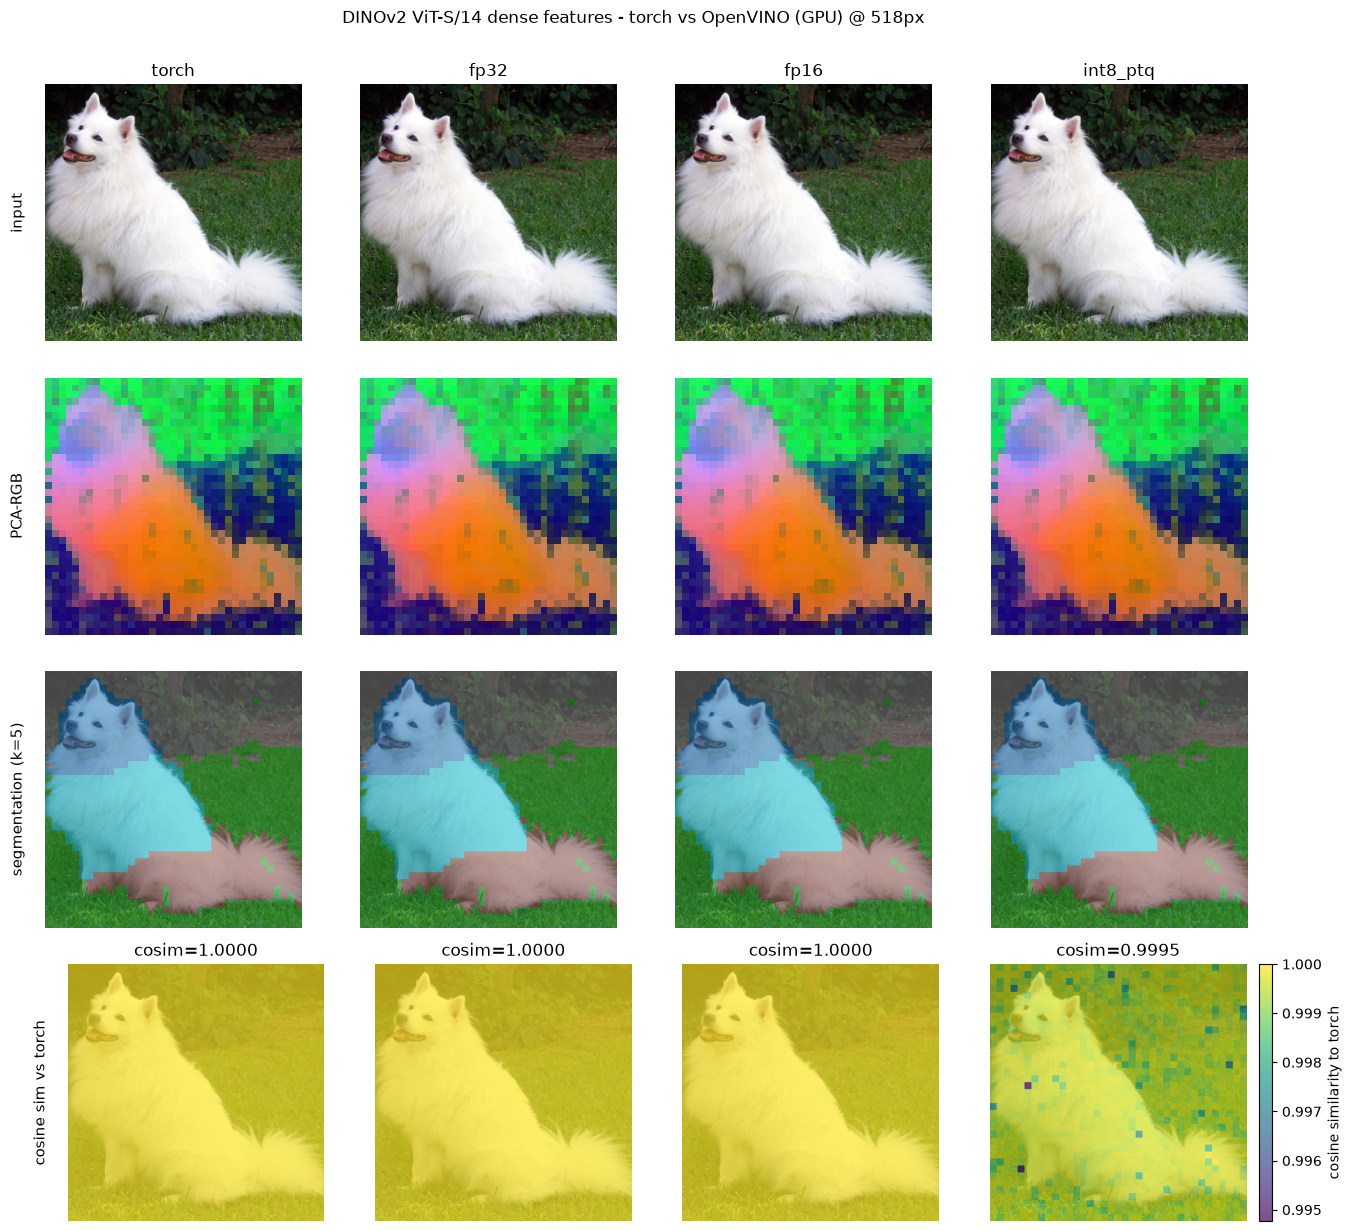

In [13]:
from sklearn.cluster import KMeans

# --- PCA basis: fit ONCE on the torch reference and reuse for every engine ----
# torch.pca_lowrank is randomized, so recomputing it per column would flip the
# sign/rotation and change colours. Fixing one basis makes the columns directly
# comparable (the same feature direction -> the same colour everywhere).
_mean = ref_rows.mean(0, keepdim=True)
_, _, _v = torch.pca_lowrank(ref_rows - _mean, q=3)
_basis = _v[:, :3]
_proj_ref = (ref_rows - _mean) @ _basis
_lo, _hi = _proj_ref.min(0).values, _proj_ref.max(0).values


def pca_rgb(feat_bdhw):
    proj = (to_rows(feat_bdhw) - _mean) @ _basis
    rgb = ((proj - _lo) / (_hi - _lo + 1e-8)).clamp(0, 1)
    return rgb.reshape(GRID, GRID, 3).cpu().numpy()


# --- segmentation: KMeans fit on torch, predicted for every precision ---------
N_SEG = 5
km = KMeans(n_clusters=N_SEG, n_init=10, random_state=0).fit(ref_rows.numpy())


def seg_grid(feat_bdhw):
    return km.predict(to_rows(feat_bdhw).numpy()).reshape(GRID, GRID)


# --- per-patch cosine similarity to the torch reference (DINO's dense measure)
def cos_sim_grid(feat_bdhw):
    hwd = feat_bdhw[0].movedim(0, -1).float()
    return F.cosine_similarity(hwd, ref_hwd, dim=-1).numpy()  # (h, w)


def upsample(grid, size, mode="nearest"):
    t = torch.from_numpy(grid.astype(np.float32))[None, None]
    return F.interpolate(t, size=(size, size), mode=mode)[0, 0].numpy()


engines = ["torch"] + list(ACTIVE)
feat_all = {"torch": ref_torch, **feats_ov}
row_titles = ["input", "PCA-RGB", f"segmentation (k={N_SEG})", "cosine sim vs torch"]

# Cosine-similarity maps; the colour range starts at the worst patch across the
# OpenVINO engines (torch's self-map is all 1.0) so the panels stay comparable
# and any precision loss is visible rather than washed out.
sim_grids = {eng: cos_sim_grid(feat_all[eng]) for eng in engines}
SIM_VMIN = min(float(sim_grids[k].min()) for k in ACTIVE)

fig, axes = plt.subplots(4, len(engines), figsize=(3.3 * len(engines), 12.2))
for j, eng in enumerate(engines):
    axes[0, j].imshow(display_np)
    axes[0, j].set_title(eng)
    axes[0, j].axis("off")
    axes[1, j].imshow(pca_rgb(feat_all[eng]))
    axes[1, j].axis("off")
    seg = upsample(seg_grid(feat_all[eng]), IMAGE_SIZE)
    axes[2, j].imshow(display_np)
    axes[2, j].imshow(seg, cmap="tab10", alpha=0.55)
    axes[2, j].axis("off")
    sim = sim_grids[eng]
    axes[3, j].imshow(display_np)
    hm = axes[3, j].imshow(upsample(sim, IMAGE_SIZE), cmap="viridis", alpha=0.7, vmin=SIM_VMIN, vmax=1.0)
    axes[3, j].set_title(f"cosim={sim.mean():.4f}")
    axes[3, j].axis("off")

for i, title in enumerate(row_titles):
    axes[i, 0].set_ylabel(title, rotation=90, labelpad=14, fontsize=11)
    axes[i, 0].axis("on")
    axes[i, 0].set_xticks([])
    axes[i, 0].set_yticks([])
    for spine in axes[i, 0].spines.values():
        spine.set_visible(False)

fig.suptitle(f"DINOv2 ViT-S/14 dense features - torch vs OpenVINO ({DEVICE}) @ {IMAGE_SIZE}px", y=1.005)
fig.tight_layout()
fig.colorbar(hm, ax=axes[3, :].tolist(), fraction=0.015, pad=0.01, label="cosine similarity to torch")
plt.show()

## 11. Summary

A compact recap of fidelity, latency and IR sizes, plus where the cached
artifacts live — the next run reuses all of them and jumps straight to
inference.

In [14]:
print("=" * 72)
print(f"DINOv2 ViT-S/14 - OpenVINO FP32 / FP16 / INT8 ({int8_method.upper()})  (device={DEVICE}, {IMAGE_SIZE}px)")
print("=" * 72)

print("\nFidelity vs torch (dense patch features):")
for k in ACTIVE:
    m = metrics[k]
    print(f"  {k:>10}: cosim={m['cosim']:.5f}  mse={m['mse']:.3e}  mae={m['mae']:.3e}")

print("\nLatency:")
for name, lat in perf.items():
    print(f"  {name:<26} {lat:7.2f} ms")

print("\nIR sizes:")
for kind in ["fp32"] + KINDS:
    path = ir_path(kind)
    if ir_on_disk(path):
        mb = path.with_suffix(".bin").stat().st_size / 1e6
        print(f"  {kind:<10} {mb:6.1f} MB")

print("\nCached artifacts (re-runs skip download + conversion):")
print(f"  weights : {CHECKPOINT_DIR}")
print(f"  image   : {SAMPLE_PATH}")
print(f"  IRs     : {FP32_DIR}")
print(f"            {FP16_DIR}")
print(f"            {INT8_DIR}")

DINOv2 ViT-S/14 - OpenVINO FP32 / FP16 / INT8 (PTQ)  (device=GPU, 518px)

Fidelity vs torch (dense patch features):
        fp32: cosim=0.99999  mse=1.101e-04  mae=8.278e-03
        fp16: cosim=0.99999  mse=1.463e-04  mae=9.397e-03
    int8_ptq: cosim=0.99948  mse=6.848e-03  mae=6.404e-02

Latency:
  torch (cpu, fp32)           154.47 ms
  torch (xpu, fp32)            42.95 ms
  ov-fp32 (GPU)                44.43 ms
  ov-fp16 (GPU)                 4.13 ms
  ov-int8_ptq (GPU)            15.76 ms

IR sizes:
  fp32         88.2 MB
  fp16         44.1 MB
  int8_ptq     32.4 MB
  int8_woq     25.1 MB

Cached artifacts (re-runs skip download + conversion):
  weights : /home/naga/projects/dinov2-s/dinov2s-v1/notebooks/dinov2-s/checkpoints/dinov2-small
  image   : /home/naga/projects/dinov2-s/dinov2s-v1/notebooks/dinov2-s/data/sample.jpg
  IRs     : /home/naga/projects/dinov2-s/dinov2s-v1/notebooks/dinov2-s/ov_models/fp32
            /home/naga/projects/dinov2-s/dinov2s-v1/notebooks/dinov2-s/o